# Avaliação no split de teste

Avalia o checkpoint treinado no split de teste (nunca visto em treino/validação): top-1/top-2, macro-F1, acurácia por grupo de Denver, matriz de confusão e métricas por classe. Salva as probabilidades softmax do teste (`test_probs.npy`), usadas na montagem do cariótipo.

No fim, compara a configuração final com uma configuração alternativa de treino, sobre os mesmos recortes de teste (teste de McNemar). Para contexto, o paper de referência reporta 94.04% de acurácia de validação na rota (b) YOLOv8 + ResNet-50 -- não comparável diretamente: o paper treina no Dataset B (Q-band, isolados e balanceados), usa outro split e filtra metáfases com sobreposição.

In [1]:
import sys
from pathlib import Path

REPO_ROOT = Path("../../..").resolve()
sys.path.insert(0, str(REPO_ROOT / "src" / "classification"))
sys.path.insert(0, str(REPO_ROOT / "src" / "preprocessing"))

from evaluate import evaluate

CHECKPOINT = Path("../runs/resnet50-paper/best.pt")  # modelo final (configuração do paper)
ALTERNATIVE = Path("../runs/resnet50-30epochs")  # configuração alternativa, comparada no fim

metrics = evaluate(CHECKPOINT)

Top-1: 0.9848  Top-2: 0.9943  Macro-F1: 0.9838
Acurácia por grupo de Denver:
  A: 0.9976
  B: 0.9903
  C: 0.9911
  D: 0.9886
  E: 0.9889
  F: 0.9830
  G: 0.9863
  X: 0.9675
  Y: 0.9492
Probabilidades salvas em: ../runs/resnet50-paper/test_probs.npy


## Matriz de confusão

Normalizada por linha (cada linha soma 100% dos cromossomos daquela classe real), com a diagonal removida para os erros ficarem visíveis -- o recall de cada classe aparece no rótulo do eixo. As linhas cinzas separam os grupos de Denver. Os erros se concentram entre classes de tamanho e forma parecidos, dentro do mesmo grupo (C6-C12, D13-D15, G21/G22) e entre grupos vizinhos (F19↔G22, X com o grupo C, Y com o grupo G) -- ver a análise de falhas no fim.

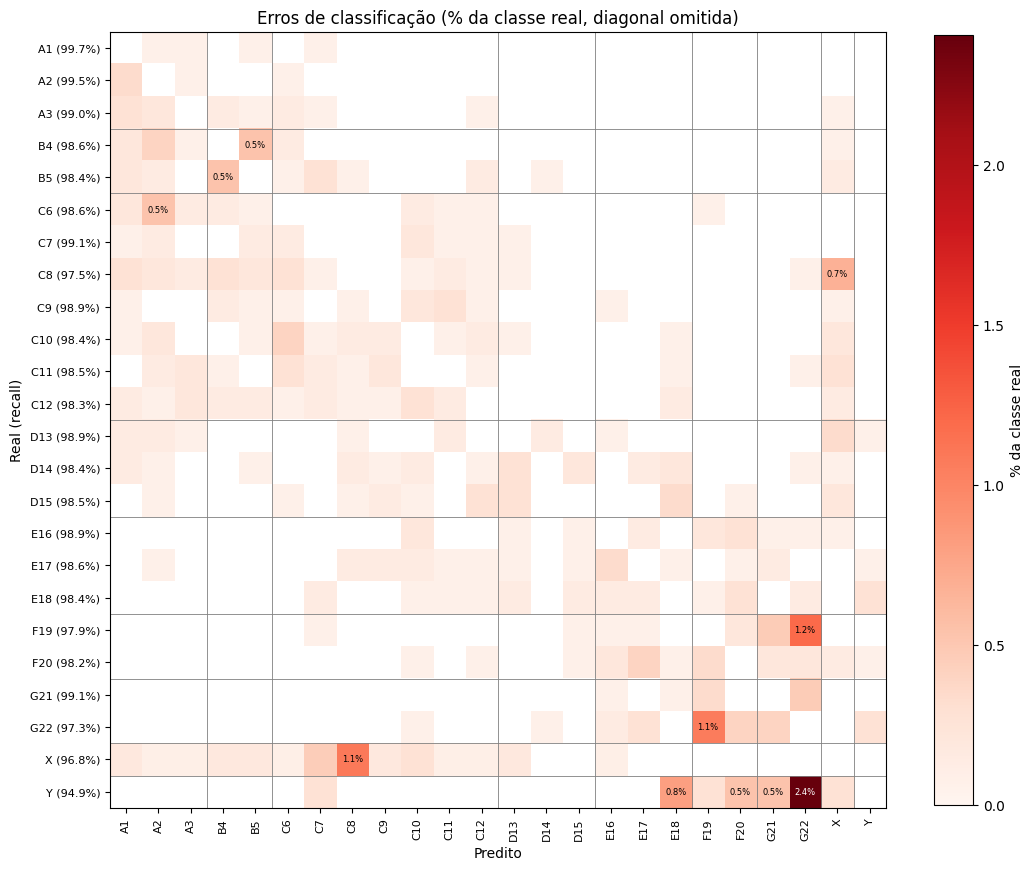

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from voc_to_yolo import DENVER_CLASSES

cm = np.array(metrics["confusion_matrix"], dtype=float)
cm_norm = cm / cm.sum(axis=1, keepdims=True)
recall = np.diag(cm_norm)
errors = cm_norm.copy()
np.fill_diagonal(errors, np.nan)
errors[errors == 0] = np.nan  # sem nenhum erro -> branco

fig, ax = plt.subplots(figsize=(11, 10))
im = ax.imshow(errors * 100, cmap="Reds", vmin=0)
n = len(DENVER_CLASSES)
ax.set_xticks(range(n))
ax.set_yticks(range(n))
ax.set_xticklabels(DENVER_CLASSES, rotation=90, fontsize=8)
ax.set_yticklabels([f"{c} ({r:.1%})" for c, r in zip(DENVER_CLASSES, recall, strict=True)], fontsize=8)
vmax = np.nanmax(errors)
for i in range(n):
    for j in range(n):
        if errors[i, j] >= 0.005:
            color = "white" if errors[i, j] > 0.6 * vmax else "black"
            ax.text(j, i, f"{errors[i, j]:.1%}", ha="center", va="center", fontsize=6, color=color)

groups = [c[0] for c in DENVER_CLASSES]
for k in range(1, n):
    if groups[k] != groups[k - 1]:
        ax.axhline(k - 0.5, color="gray", linewidth=0.6)
        ax.axvline(k - 0.5, color="gray", linewidth=0.6)

ax.set_xlabel("Predito")
ax.set_ylabel("Real (recall)")
ax.set_title("Erros de classificação (% da classe real, diagonal omitida)")
fig.colorbar(im, label="% da classe real", shrink=0.8)
plt.tight_layout()
(REPO_ROOT / "outputs" / "figures" / "classifier").mkdir(parents=True, exist_ok=True)
fig.savefig(REPO_ROOT / "outputs" / "figures" / "classifier" / "test_confusion_errors.png", dpi=200)
plt.show()

## Métricas por classe

Precisão, recall, F1 e AUC-ROC (one-vs-rest) de cada uma das 24 classes, ordenadas pelo F1 -- as piores no topo. A tabela completa vai para `outputs/figures/classifier/test_per_class.csv`.

In [3]:
import pandas as pd
from metrics import classification_metrics

FIGURES = REPO_ROOT / "outputs" / "figures" / "classifier"
FIGURES.mkdir(parents=True, exist_ok=True)

probs = np.load(CHECKPOINT.parent / "test_probs.npy")
labels = np.load(CHECKPOINT.parent / "test_labels.npy")
preds = probs.argmax(axis=1)

test_metrics = classification_metrics(probs, labels)
per_class = pd.DataFrame(
    {
        "precisão": test_metrics["per_class"]["precision"],
        "recall": test_metrics["per_class"]["recall"],
        "F1": test_metrics["per_class"]["f1"],
        "AUC-ROC": test_metrics["per_class"]["auc"],
        "n": test_metrics["per_class"]["support"],
    },
    index=DENVER_CLASSES,
)
per_class.round(4).to_csv(FIGURES / "test_per_class.csv")
per_class.sort_values("F1").round(4)

,precisão,recall,F1,AUC-ROC,n
Y,0.9699,0.9492,0.9595,0.9999,374
X,0.9666,0.9675,0.9671,0.9987,1108
G22,0.9713,0.9733,0.9723,0.9992,1497
F19,0.9787,0.9787,0.9787,0.9994,1499
C8,0.9838,0.9753,0.9796,0.9995,1498
C10,0.9820,0.9840,0.9830,0.9997,1497
F20,0.9859,0.9820,0.9839,0.9996,1498
B5,0.9846,0.9840,0.9843,0.9998,1499
C6,0.9827,0.9860,0.9843,0.9996,1498
C12,0.9872,0.9833,0.9853,0.9996,1496


## Resumo com intervalo de confiança

Acurácia, precisão/recall/F1 macro e AUC-ROC macro (one-vs-rest) no teste, com intervalo de confiança de 95% por bootstrap (1000 reamostragens, percentil). A reamostragem é **por metáfase**, não por recorte: os ~46 cromossomos de uma mesma metáfase compartilham coloração, resolução e qualidade da imagem, então não são amostras independentes -- reamostrá-los um a um daria um intervalo estreito demais.

A AUC-ROC aqui é a média das 24 curvas one-vs-rest (cada classe contra as demais), calculada sobre as probabilidades do softmax, não só sobre a classe prevista.

In [4]:
from dataset import load_manifest
from metrics import bootstrap_ci, macro_prf
from sklearn.metrics import roc_auc_score
from train import MANIFEST

# o evaluate percorre o manifest de teste em ordem, então a linha i dos .npy é o recorte i do manifest
test_rows = load_manifest(MANIFEST, "test")
assert [int(r["class_id"]) for r in test_rows] == labels.tolist()
metaphase = np.array([r["image"] for r in test_rows])

n_classes = len(DENVER_CLASSES)
point_metrics = {
    "Acurácia": lambda p, y: float((p.argmax(axis=1) == y).mean()),
    "Precisão (macro)": lambda p, y: macro_prf(p.argmax(axis=1), y, n_classes)[0],
    "Recall (macro)": lambda p, y: macro_prf(p.argmax(axis=1), y, n_classes)[1],
    "F1 (macro)": lambda p, y: macro_prf(p.argmax(axis=1), y, n_classes)[2],
    "AUC-ROC (macro, OvR)": lambda p, y: float(
        roc_auc_score(y, p, multi_class="ovr", average="macro", labels=range(n_classes))
    ),
}

summary_rows = {}
for name, metric in point_metrics.items():
    low, high = bootstrap_ci(probs, labels, metric, n_resamples=1000, groups=metaphase)
    summary_rows[name] = {"valor": metric(probs, labels), "IC 95% inf.": low, "IC 95% sup.": high}

summary = pd.DataFrame(summary_rows).T
summary.round(4).to_csv(FIGURES / "test_summary_ci.csv")
print(f"{len(labels)} recortes de {len(set(metaphase))} metáfases de teste")
summary.round(4)

34434 recortes de 749 metáfases de teste


,valor,IC 95% inf.,IC 95% sup.
Acurácia,0.9848,0.9830,0.9865
Precisão (macro),0.9841,0.9821,0.9859
Recall (macro),0.9835,0.9815,0.9854
F1 (macro),0.9838,0.9818,0.9856
"AUC-ROC (macro, OvR)",0.9997,0.9995,0.9998


## Curvas ROC (one-vs-rest)

Uma curva por classe (cada classe contra as outras 23). Como todas ficam coladas no canto superior esquerdo (AUC > 0,99), o eixo da taxa de falsos positivos está em escala logarítmica -- é onde as classes se diferenciam. Destacadas as quatro classes de menor AUC; as demais em cinza.

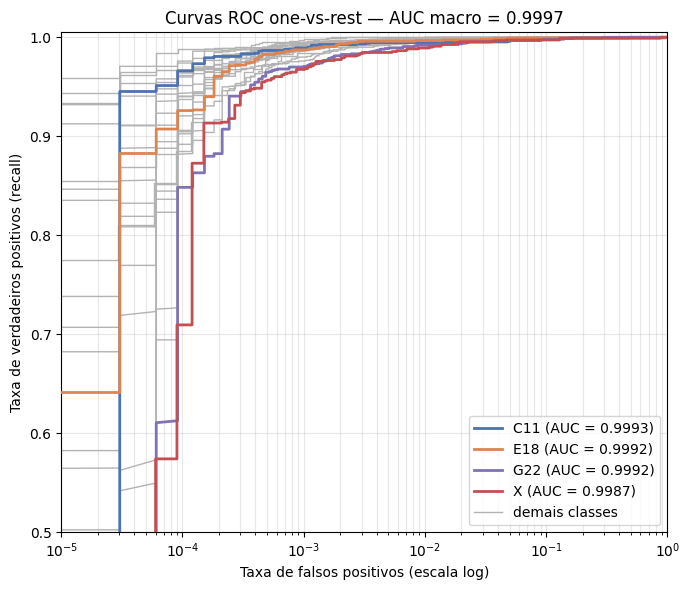

In [5]:
from sklearn.metrics import roc_curve

worst = per_class["AUC-ROC"].nsmallest(4).index.tolist()
highlight_colors = dict(zip(worst, ["#C44E52", "#DD8452", "#8172B3", "#4C72B0"], strict=True))

fig, ax = plt.subplots(figsize=(7, 6))
for c, name in enumerate(DENVER_CLASSES):
    fpr, tpr, _ = roc_curve(labels == c, probs[:, c])
    if name in highlight_colors:
        ax.plot(fpr, tpr, color=highlight_colors[name], lw=2,
                label=f"{name} (AUC = {per_class.loc[name, 'AUC-ROC']:.4f})", zorder=3)
    else:
        ax.plot(fpr, tpr, color="0.7", lw=1, zorder=1)
ax.plot([], [], color="0.7", lw=1, label="demais classes")
ax.set_xscale("log")
ax.set_xlim(1e-5, 1)
ax.set_ylim(0.5, 1.005)
ax.set_xlabel("Taxa de falsos positivos (escala log)")
ax.set_ylabel("Taxa de verdadeiros positivos (recall)")
ax.set_title(f"Curvas ROC one-vs-rest — AUC macro = {test_metrics['macro_auc']:.4f}")
ax.grid(alpha=0.3, which="both")
ax.legend(loc="lower right")
plt.tight_layout()
fig.savefig(FIGURES / "test_roc_ovr.png", dpi=200)
plt.show()

## Comparação com uma configuração alternativa

A configuração final (a do paper: recorte esticado, Adam e early stopping) é comparada com uma alternativa de 30 épocas, com letterbox (preserva a proporção do recorte), rotação livre e AdamW com cosine. As duas são avaliadas sobre exatamente os mesmos recortes de teste, então dá para comparar recorte a recorte. O teste de McNemar (exato) olha só os casos em que uma configuração acerta e a outra erra, e diz se esse desequilíbrio pode ser explicado por acaso -- p < 0,05 indica diferença real. Com um único treino por configuração, diferenças pequenas e com p alto devem ser tratadas como ruído.

Observação: aqui a acurácia é da **classe exata** (A1 previsto como A2 conta como erro). A "acurácia por grupo de Denver" impressa pelo `evaluate` no início é mais tolerante -- conta como acerto qualquer predição dentro do grupo certo. Para X e Y as duas coincidem.

In [6]:
from scipy.stats import binomtest

alt_labels = np.load(ALTERNATIVE / "test_labels.npy")
assert np.array_equal(alt_labels, labels), "as configurações não usam o mesmo split de teste"
alt_preds = np.load(ALTERNATIVE / "test_probs.npy").argmax(axis=1)

class_group = np.array([c[0] for c in DENVER_CLASSES])
subsets = {"geral": np.ones_like(labels, dtype=bool)}
subsets |= {g: class_group[labels] == g for g in "ABCDEFG"}
subsets |= {c: labels == DENVER_CLASSES.index(c) for c in ("X", "Y")}

rows = []
for mask in subsets.values():
    alt_ok, final_ok = alt_preds[mask] == labels[mask], preds[mask] == labels[mask]
    only_alt, only_final = int((alt_ok & ~final_ok).sum()), int((~alt_ok & final_ok).sum())
    discordant = only_alt + only_final
    rows.append({
        "n": int(mask.sum()),
        "acc. exata alternativa": alt_ok.mean(),
        "acc. exata final": final_ok.mean(),
        "só alternativa acerta": only_alt,
        "só final acerta": only_final,
        "p (McNemar)": binomtest(only_final, discordant, 0.5).pvalue if discordant else 1.0,
    })
pd.DataFrame(rows, index=list(subsets)).round(4)

,n,acc. exata alternativa,acc. exata final,só alternativa acerta,só final acerta,p (McNemar)
geral,34434,0.9822,0.9848,229,319,0.0001
A,4493,0.9927,0.9942,19,26,0.3713
B,2996,0.9790,0.9850,22,40,0.0300
C,10483,0.9804,0.9848,62,108,0.0005
D,4493,0.9855,0.9858,33,34,1.0000
E,4494,0.9844,0.9862,28,36,0.3817
F,2997,0.9783,0.9803,19,25,0.4514
G,2996,0.9750,0.9820,17,38,0.0065
X,1108,0.9765,0.9675,16,6,0.0525
Y,374,0.9679,0.9492,13,6,0.1671


## Análise de falhas

Os recortes vêm das caixas anotadas (não do detector), então esta seção isola os erros do classificador. Três perguntas: o classificador erra mais nas metáfases que os autores do dataset marcaram como difíceis (`diff_image.txt`: fundo escuro, sobreposição)? Quais classes ele confunde entre si? E quão confiante ele está quando erra -- um erro com confiança alta é o mais perigoso para o alerta de aneuploidia, porque não dá para filtrá-lo pela probabilidade.

In [7]:
sys.path.insert(0, str(REPO_ROOT / "src" / "detection"))
from evaluate_detector import difficult_images


def accuracy(p, y):
    return float((p.argmax(axis=1) == y).mean())


is_hard = np.isin(metaphase, sorted(difficult_images()))
hard_rows = {}
for name, mask in (("difíceis", is_hard), ("demais", ~is_hard)):
    low, high = bootstrap_ci(probs[mask], labels[mask], accuracy, n_resamples=1000, groups=metaphase[mask])
    hard_rows[name] = {
        "metáfases": len(set(metaphase[mask])), "recortes": int(mask.sum()),
        "acurácia": accuracy(probs[mask], labels[mask]), "IC 95% inf.": low, "IC 95% sup.": high,
    }
hard_table = pd.DataFrame(hard_rows).T
hard_table.to_csv(FIGURES / "test_difficult_vs_others.csv")
hard_table.round(4)

,metáfases,recortes,acurácia,IC 95% inf.,IC 95% sup.
difíceis,20.0,920.0,0.9946,0.9891,0.9989
demais,729.0,33514.0,0.9845,0.9827,0.9862


Pares de classes mais confundidos (real → previsto), em número de recortes e em parcela de todos os erros do teste.

In [8]:
n_errors = int(cm.sum() - np.trace(cm))
pairs = pd.DataFrame(
    [
        {"real": DENVER_CLASSES[i], "previsto": DENVER_CLASSES[j], "recortes": int(cm[i, j]),
         "% da classe real": 100 * cm[i, j] / cm[i].sum(), "% dos erros": 100 * cm[i, j] / n_errors}
        for i in range(n_classes) for j in range(n_classes) if i != j and cm[i, j] > 0
    ]
).sort_values("recortes", ascending=False)
pairs.round(2).to_csv(FIGURES / "test_confused_pairs.csv", index=False)

wrong = preds != labels
same_group = class_group[preds[wrong]] == class_group[labels[wrong]]
print(f"{n_errors} erros; {same_group.mean():.0%} deles dentro do mesmo grupo de Denver")
pairs.head(10).round(2)

524 erros; 27% deles dentro do mesmo grupo de Denver


,real,previsto,recortes,% da classe real,% dos erros
178,F19,G22,18,1.20,3.44
198,G22,F19,16,1.07,3.05
209,X,C8,12,1.08,2.29
59,C8,X,10,0.67,1.91
221,Y,G22,9,2.41,1.72
23,B5,B4,8,0.53,1.53
18,B4,B5,8,0.53,1.53
31,C6,A2,8,0.53,1.53
177,F19,G21,7,0.47,1.34
193,G21,G22,7,0.47,1.34


Confiança da classe prevista nos erros e nos acertos, e os erros mais confiantes (`* = metáfase difícil`).

confiança ≥ 0.5: 84% dos erros, 100% dos acertos
confiança ≥ 0.9: 33% dos erros, 98% dos acertos
confiança ≥ 0.99: 15% dos erros, 95% dos acertos


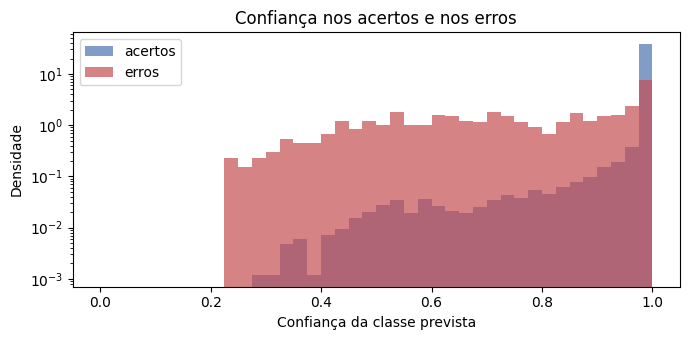

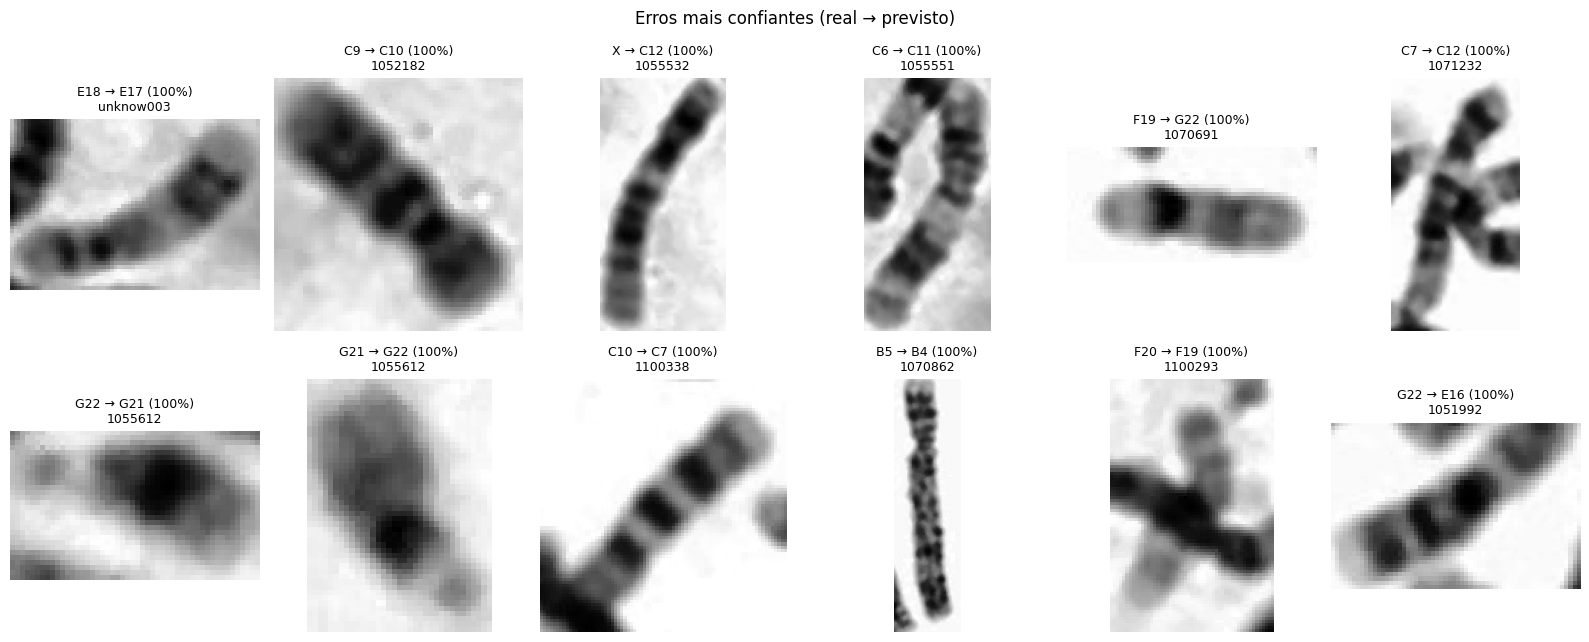

In [9]:
import cv2
from train import CROPS_ROOT

confidence = probs.max(axis=1)
for threshold in (0.5, 0.9, 0.99):
    print(f"confiança ≥ {threshold}: {(confidence[wrong] >= threshold).mean():.0%} dos erros, "
          f"{(confidence[~wrong] >= threshold).mean():.0%} dos acertos")

fig, ax = plt.subplots(figsize=(7, 3.5))
bins = np.linspace(0, 1, 41)
ax.hist(confidence[~wrong], bins=bins, color="#4C72B0", alpha=0.7, density=True, label="acertos")
ax.hist(confidence[wrong], bins=bins, color="#C44E52", alpha=0.7, density=True, label="erros")
ax.set(xlabel="Confiança da classe prevista", ylabel="Densidade", yscale="log", title="Confiança nos acertos e nos erros")
ax.legend()
plt.tight_layout()
plt.show()

top_errors = np.where(wrong)[0][np.argsort(-confidence[wrong])][:12]
fig, axes = plt.subplots(2, 6, figsize=(16, 6.5))
for ax, i in zip(axes.flat, top_errors, strict=True):
    row = test_rows[i]
    ax.imshow(cv2.imread(str(CROPS_ROOT / row["path"]), cv2.IMREAD_GRAYSCALE), cmap="gray")
    star = "*" if is_hard[i] else ""
    ax.set_title(f"{DENVER_CLASSES[labels[i]]} → {DENVER_CLASSES[preds[i]]} ({confidence[i]:.0%})\n{row['image']}{star}", fontsize=9)
    ax.axis("off")
fig.suptitle("Erros mais confiantes (real → previsto)")
plt.tight_layout()
fig.savefig(FIGURES / "test_confident_errors.png", dpi=150)
plt.show()

### Conclusões da análise de falhas

- **Metáfases difíceis.** O classificador não erra mais nelas -- a acurácia é até maior que nas demais. A dificuldade dessas imagens está em separar os cromossomos (fundo escuro, sobreposição), que é tarefa do detector; recebendo a caixa anotada, o classificador não sofre. Com só 20 metáfases, o intervalo é largo.
- **O que ele confunde.** Classes de tamanho e forma parecidos, mas na maioria das vezes de grupos de Denver vizinhos, não do mesmo grupo: F19↔G22, X↔C8, Y→G22, B4↔B5, C6→A2. Por isso a "acurácia por grupo" do início é só um pouco mais alta que a exata.
- **Erros confiantes.** Um terço dos erros tem confiança ≥ 90%, então um limiar de probabilidade não basta para filtrá-los antes do alerta numérico. A galeria mostra dois casos típicos: cromossomos cruzados com um vizinho dentro do recorte e homólogos trocados na mesma metáfase (um G21 previsto como G22 e o G22 como G21). A troca não altera a contagem por classe, então não gera falso alerta.